In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
df=pd.read_csv("thyroid_dataset.csv")

df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [5]:
X=df.drop("Outlier_label", axis=1)
y=df["Outlier_label"]

In [7]:
scaler=StandardScaler()

X_scaled=scaler.fit_transform(X)

In [8]:
from sklearn.ensemble import IsolationForest

clf=IsolationForest(n_estimators=200, contamination="auto", random_state=42)

In [9]:
labels=clf.fit_predict(X_scaled)

In [10]:
#visualization

from sklearn.decomposition import PCA

pca=PCA(n_components=2)

X_pca=pca.fit_transform(X_scaled)

<Axes: >

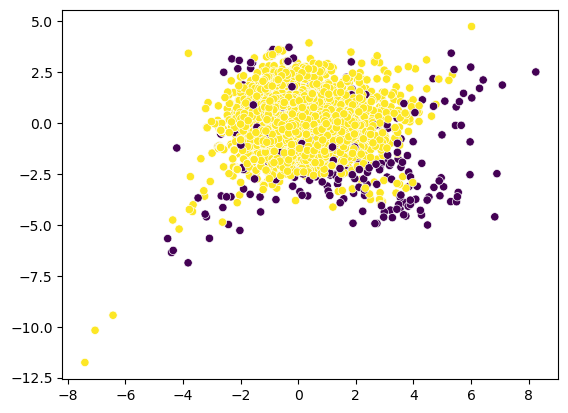

In [15]:
import seaborn as sns

sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], c=labels)

### LOF

In [16]:
from sklearn.neighbors import LocalOutlierFactor

neighbs=LocalOutlierFactor()

In [17]:
labels=neighbs.fit_predict(X_scaled)

C:\Users\punja\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\punja\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\punja\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\punja\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

<Axes: >

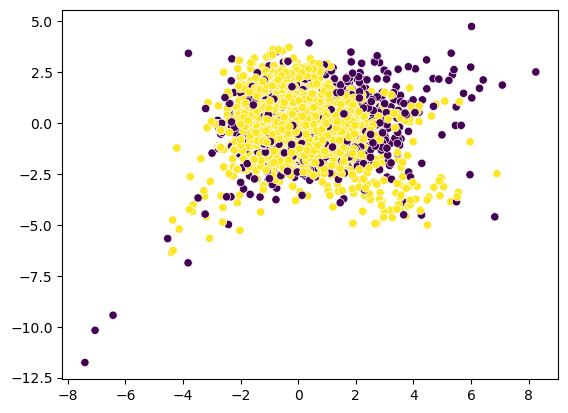

In [18]:
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], c=labels)